In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
movies = pd.read_csv("data/movies.csv")
tags = pd.read_csv("data/tags.csv")
ratings = pd.read_csv("data/ratings.csv")

print("movies :", movies.shape)
print("tags   :", tags.shape)
print("ratings:", ratings.shape)
print(f"Kullanıcı: {ratings['userId'].nunique()} | puan ölçeği: {sorted(ratings['rating'].unique())}")

movies : (9742, 3)
tags   : (3683, 4)
ratings: (100836, 4)
Kullanıcı: 610 | puan ölçeği: [np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0)]


In [3]:
movies["genres"] = movies["genres"].str.replace("|", " ", regex=False)
movies = movies[movies["movieId"].isin(ratings["movieId"])].reset_index(drop=True)

print("Puan almış film:", movies.shape)
print("genres içinde '|' kalan satır:", int(movies["genres"].str.contains("|", regex=False).sum()))
movies.head()

Puan almış film: (9724, 3)
genres içinde '|' kalan satır: 0


,movieId,title,genres
0,1,Toy Story (1995),Adventure Animation Children Comedy Fantasy
1,2,Jumanji (1995),Adventure Children Fantasy
2,3,Grumpier Old Men (1995),Comedy Romance
3,4,Waiting to Exhale (1995),Comedy Drama Romance
4,5,Father of the Bride Part II (1995),Comedy


In [4]:
movie_tags = tags.groupby("movieId")["tag"].apply(lambda x: " ".join(x.astype(str))).reset_index()

merged_df = movies.merge(movie_tags, on="movieId", how="left")
merged_df["tag"] = merged_df["tag"].fillna("")
merged_df["metadata"] = (merged_df["tag"] + " " + merged_df["genres"]).str.strip()

print("merged_df:", merged_df.shape, "| benzersiz movieId:", merged_df["movieId"].is_unique)
print("Etiketi olan film:", int((merged_df["tag"] != "").sum()))
merged_df.loc[merged_df["title"].isin(["Toy Story (1995)", "Copycat (1995)"]), ["movieId", "title", "metadata"]]

merged_df: (9724, 5) | benzersiz movieId: True
Etiketi olan film: 1554


,movieId,title,metadata
0,1,Toy Story (1995),pixar pixar fun Adventure Animation Children C...
21,22,Copycat (1995),serial killer Crime Drama Horror Mystery Thriller


In [5]:
count = CountVectorizer(stop_words="english")
count_matrix = count.fit_transform(merged_df["metadata"])
count_df = pd.DataFrame(count_matrix.toarray(), index=merged_df["movieId"], columns=count.get_feature_names_out())

print("count_df:", count_df.shape)
print(f"Doluluk oranı: {count_matrix.nnz / np.prod(count_matrix.shape):.2%}")

count_df: (9724, 1675)
Doluluk oranı: 0.17%


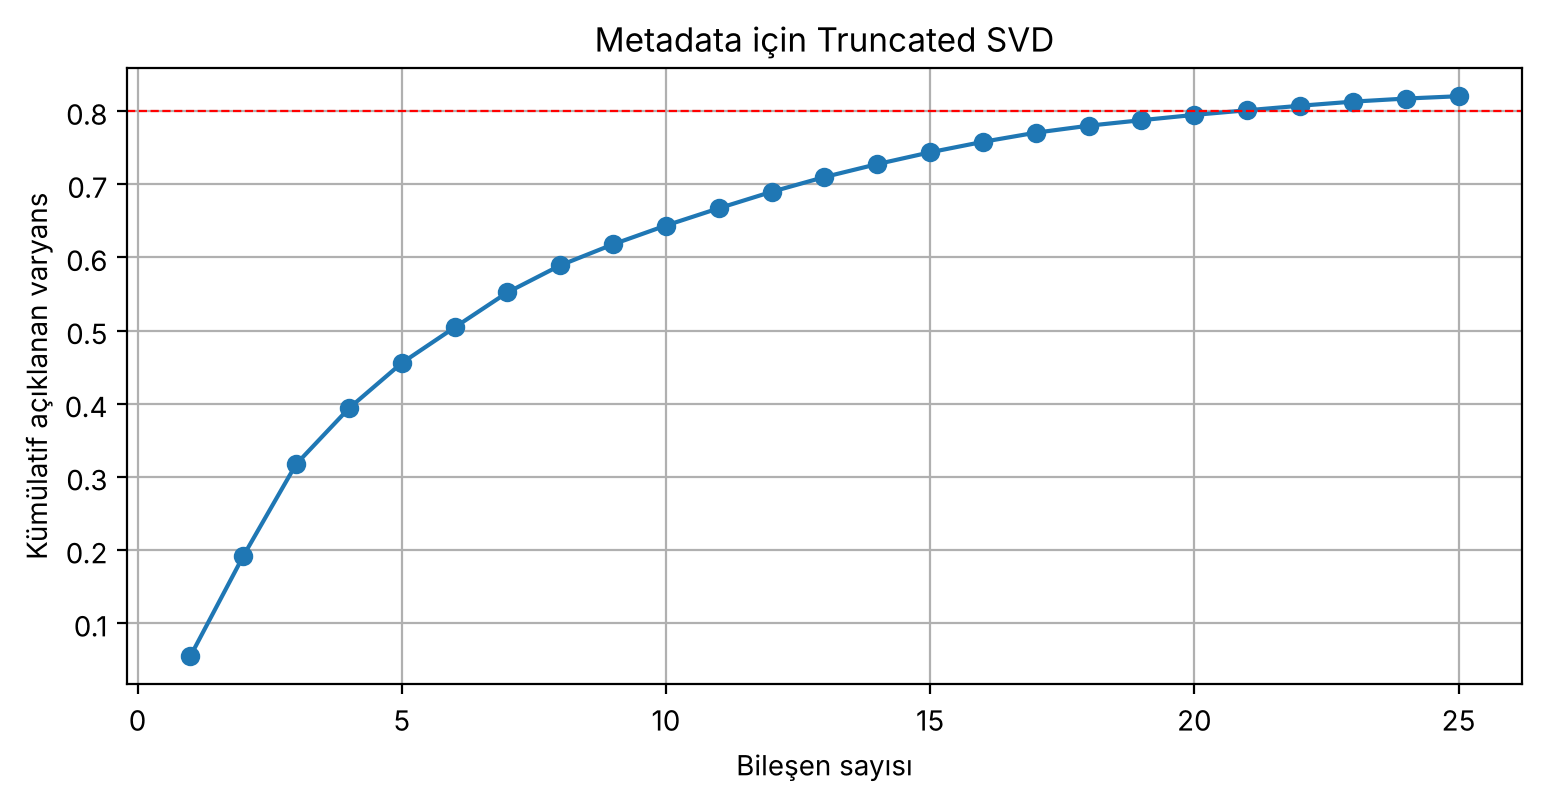

25 bileşenin açıkladığı varyans: 82.0%
latent_df: (9724, 25)


In [6]:
svd = TruncatedSVD(n_components=25, random_state=42)
latent_matrix = svd.fit_transform(count_matrix)

plt.figure(figsize=(9, 4))
plt.plot(range(1, 26), np.cumsum(svd.explained_variance_ratio_), marker="o")
plt.axhline(0.8, color="red", linestyle="--", linewidth=0.8)
plt.xlabel("Bileşen sayısı")
plt.ylabel("Kümülatif açıklanan varyans")
plt.title("Metadata için Truncated SVD")
plt.grid()
plt.show()

latent_df = pd.DataFrame(latent_matrix, index=merged_df["title"])
print(f"25 bileşenin açıkladığı varyans: {svd.explained_variance_ratio_.sum():.1%}")
print("latent_df:", latent_df.shape)

In [7]:
terms = count.get_feature_names_out()
for i in range(5):
    top = np.argsort(-svd.components_[i])[:8]
    print(f"Bileşen {i + 1}: {', '.join(terms[top])}")

Bileşen 1: drama, comedy, thriller, action, romance, crime, adventure, fi
Bileşen 2: comedy, romance, children, animation, fantasy, musical, dark, funny
Bileşen 3: drama, romance, war, netflix, queue, musical, shakespeare, death
Bileşen 4: thriller, crime, comedy, horror, mystery, action, noir, film
Bileşen 5: adventure, action, children, fantasy, crime, animation, war, imax


In [8]:
ratings1 = pd.merge(movies[["movieId"]], ratings, on="movieId", how="right")
ratings2 = ratings1.pivot(index="movieId", columns="userId", values="rating").fillna(0)

print("ratings2:", ratings2.shape)
print(f"Doluluk oranı: {(ratings2 > 0).values.mean():.2%}")
print("Satır sırası merged_df ile aynı mı:", bool((ratings2.index.values == merged_df["movieId"].values).all()))

ratings2: (9724, 610)
Doluluk oranı: 1.70%
Satır sırası merged_df ile aynı mı: True


In [9]:
svd_2 = TruncatedSVD(n_components=200, random_state=42)
latent_matrix_2 = svd_2.fit_transform(ratings2)
latent_df_2 = pd.DataFrame(latent_matrix_2, index=merged_df["title"])

print(f"200 bileşenin açıkladığı varyans: {svd_2.explained_variance_ratio_.sum():.1%}")
print("latent_df_2:", latent_df_2.shape)
print("Tekrar eden film adı:", int(merged_df["title"].duplicated().sum()))

200 bileşenin açıkladığı varyans: 85.8%
latent_df_2: (9724, 200)
Tekrar eden film adı: 5


In [10]:
n_ratings = ratings.groupby("movieId").size().reindex(merged_df["movieId"]).values
mean_rating = ratings.groupby("movieId")["rating"].mean().reindex(merged_df["movieId"]).values

def similarities(title):
    i = int(np.flatnonzero(merged_df["title"].values == title)[0])
    content = cosine_similarity(latent_matrix[i:i + 1], latent_matrix)[0]
    collaborative = cosine_similarity(latent_matrix_2[i:i + 1], latent_matrix_2)[0]
    return pd.DataFrame({
        "title": merged_df["title"].values,
        "genres": merged_df["genres"].values,
        "n_ratings": n_ratings,
        "content": content,
        "collaborative": collaborative,
        "hybrid": (content + collaborative) / 2,
    })

similarity_df = similarities("Toy Story (1995)")
similarity_df.sort_values("collaborative", ascending=False).head(11).round(3)

,title,genres,n_ratings,content,collaborative,hybrid
0,Toy Story (1995),Adventure Animation Children Comedy Fantasy,215,1.000,1.000,1.000
2353,Toy Story 2 (1999),Adventure Animation Children Comedy Fantasy,97,0.947,0.642,0.794
615,Independence Day (a.k.a. ID4) (1996),Action Adventure Sci-Fi Thriller,202,0.198,0.625,0.412
418,Jurassic Park (1993),Action Adventure Sci-Fi Thriller,238,0.199,0.611,0.405
546,Mission: Impossible (1996),Action Adventure Mystery Thriller,162,0.222,0.603,0.413
224,Star Wars: Episode IV - A New Hope (1977),Action Adventure Sci-Fi,251,0.094,0.592,0.343
3189,Shrek (2001),Adventure Animation Children Comedy Fantasy Ro...,170,0.912,0.588,0.750
322,"Lion King, The (1994)",Adventure Animation Children Drama Musical IMAX,172,0.527,0.584,0.555
910,Star Wars: Episode VI - Return of the Jedi (1983),Action Adventure Sci-Fi,196,0.191,0.580,0.385
314,Forrest Gump (1994),Comedy Drama Romance War,329,0.221,0.579,0.400


In [11]:
similarity_df.sort_values("content", ascending=False).head(11).round(3)

,title,genres,n_ratings,content,collaborative,hybrid
0,Toy Story (1995),Adventure Animation Children Comedy Fantasy,215,1.0,1.000,1.000
2805,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure Animation Children Comedy Fantasy,9,1.0,0.164,0.582
2996,"Emperor's New Groove, The (2000)",Adventure Animation Children Comedy Fantasy,37,1.0,0.304,0.652
6469,Shrek the Third (2007),Adventure Animation Children Comedy Fantasy,21,1.0,0.206,0.603
7742,Asterix and the Vikings (Astérix et les Viking...,Adventure Animation Children Comedy Fantasy,1,1.0,0.052,0.526
6177,"Wild, The (2006)",Adventure Animation Children Comedy Fantasy,1,1.0,0.068,0.534
6931,"Tale of Despereaux, The (2008)",Adventure Animation Children Comedy Fantasy,1,1.0,0.077,0.539
8201,Turbo (2013),Adventure Animation Children Comedy Fantasy,1,1.0,0.089,0.544
9412,Moana (2016),Adventure Animation Children Comedy Fantasy,10,1.0,0.067,0.533
1705,Antz (1998),Adventure Animation Children Comedy Fantasy,45,1.0,0.393,0.697


In [12]:
similarity_df.sort_values("hybrid", ascending=False).head(11).round(3)

,title,genres,n_ratings,content,collaborative,hybrid
0,Toy Story (1995),Adventure Animation Children Comedy Fantasy,215,1.000,1.000,1.000
2353,Toy Story 2 (1999),Adventure Animation Children Comedy Fantasy,97,0.947,0.642,0.794
3563,"Monsters, Inc. (2001)",Adventure Animation Children Comedy Fantasy,132,1.000,0.554,0.777
3189,Shrek (2001),Adventure Animation Children Comedy Fantasy Ro...,170,0.912,0.588,0.750
1756,"Bug's Life, A (1998)",Adventure Animation Children Comedy,92,0.896,0.528,0.712
4354,Finding Nemo (2003),Adventure Animation Children Comedy,141,0.896,0.525,0.710
1705,Antz (1998),Adventure Animation Children Comedy Fantasy,45,1.000,0.393,0.697
7338,Toy Story 3 (2010),Adventure Animation Children Comedy Fantasy IMAX,55,0.913,0.477,0.695
506,Aladdin (1992),Adventure Animation Children Comedy Musical,183,0.795,0.577,0.686
3740,Ice Age (2002),Adventure Animation Children Comedy,85,0.896,0.434,0.665


In [13]:
def recommend(title, method="hybrid", n=10):
    df = similarities(title)
    return df[df["title"] != title].sort_values(method, ascending=False)["title"].head(n).tolist()

for title in ["Matrix, The (1999)", "Godfather, The (1972)", "Lord of the Rings: The Fellowship of the Ring, The (2001)"]:
    print(title)
    for method in ["content", "collaborative", "hybrid"]:
        print(f"  {method:<13}: {', '.join(recommend(title, method, 5))}")
    print()

Matrix, The (1999)
  content      : Predator (1987), Blade Runner (1982), Terminator, The (1984), eXistenZ (1999), Cowboy Bebop: The Movie (Cowboy Bebop: Tengoku no Tobira) (2001)
  collaborative: Fight Club (1999), Star Wars: Episode V - The Empire Strikes Back (1980), Saving Private Ryan (1998), Star Wars: Episode VI - Return of the Jedi (1983), Sixth Sense, The (1999)
  hybrid       : Terminator, The (1984), Blade Runner (1982), Terminator 2: Judgment Day (1991), Star Wars: Episode V - The Empire Strikes Back (1980), Spider-Man (2002)

Godfather, The (1972)
  content      : Casino (1995), Goodfellas (1990), Donnie Brasco (1997), Bonnie and Clyde (1967), Serpico (1973)
  collaborative: Godfather: Part II, The (1974), Goodfellas (1990), One Flew Over the Cuckoo's Nest (1975), Star Wars: Episode IV - A New Hope (1977), Fargo (1996)
  hybrid       : Godfather: Part II, The (1974), Goodfellas (1990), Shawshank Redemption, The (1994), Green Mile, The (1999), No Country for Old Men (2007)


In [14]:
franchises = {
    "Toy Story (1995)": "Toy Story",
    "Harry Potter and the Sorcerer's Stone (a.k.a. Harry Potter and the Philosopher's Stone) (2001)": "Harry Potter",
    "Lord of the Rings: The Fellowship of the Ring, The (2001)": "Lord of the Rings",
    "Matrix, The (1999)": "Matrix",
    "Star Wars: Episode IV - A New Hope (1977)": "Star Wars",
    "Shrek (2001)": "Shrek",
    "Godfather, The (1972)": "Godfather",
    "Pirates of the Caribbean: The Curse of the Black Pearl (2003)": "Pirates of the Caribbean",
    "Bourne Identity, The (2002)": "Bourne",
    "Back to the Future (1985)": "Back to the Future",
    "Terminator, The (1984)": "Terminator",
    "Indiana Jones and the Temple of Doom (1984)": "Indiana Jones",
}

rows = []
for title, keyword in franchises.items():
    siblings = set(merged_df.loc[merged_df["title"].str.contains(keyword, regex=False) & (merged_df["title"] != title), "title"])
    df = similarities(title)
    df = df[df["title"] != title]
    row = {"film": title[:40], "seri_filmi": len(siblings)}
    for method in ["content", "collaborative", "hybrid"]:
        top = df.sort_values(method, ascending=False).head(10)
        row[method] = len(siblings & set(top["title"]))
    rows.append(row)

franchise_eval = pd.DataFrame(rows)
print("İlk 10 öneride yakalanan aynı seri filmi sayısı:")
print(franchise_eval.to_string(index=False))
print("\nToplam:", franchise_eval[["seri_filmi", "content", "collaborative", "hybrid"]].sum().to_dict())

İlk 10 öneride yakalanan aynı seri filmi sayısı:
                                    film  seri_filmi  content  collaborative  hybrid
                        Toy Story (1995)           2        0              1       2
Harry Potter and the Sorcerer's Stone (a           7        0              5       3
Lord of the Rings: The Fellowship of the           3        1              2       2
                      Matrix, The (1999)           2        0              0       0
Star Wars: Episode IV - A New Hope (1977          12        3              3       4
                            Shrek (2001)           4        1              1       1
                   Godfather, The (1972)           4        0              1       1
Pirates of the Caribbean: The Curse of t           4        1              1       2
             Bourne Identity, The (2002)           5        0              2       2
               Back to the Future (1985)           3        1              2       2
                

In [15]:
popular = merged_df.loc[n_ratings >= 100, "title"].tolist()
rng = np.random.RandomState(42)
sample = rng.choice(popular, size=50, replace=False)

profile = []
for title in sample:
    df = similarities(title)
    df = df[df["title"] != title]
    query_genres = set(merged_df.loc[merged_df["title"] == title, "genres"].values[0].split())
    for method in ["content", "collaborative", "hybrid"]:
        top = df.sort_values(method, ascending=False).head(10)
        profile.append({
            "method": method,
            "medyan_puan_sayısı": np.median(top["n_ratings"]),
            "ortak_tür_oranı": np.mean([len(query_genres & set(g.split())) > 0 for g in top["genres"]]),
            "seçilen_puan_sayısı>=50": np.mean(top["n_ratings"] >= 50),
        })

pd.DataFrame(profile).groupby("method").mean().round(3)

,medyan_puan_sayısı,ortak_tür_oranı,seçilen_puan_sayısı>=50
method,,,
collaborative,139.68,0.810,0.996
content,14.28,0.984,0.168
hybrid,90.52,1.000,0.788


In [16]:
a = "content"
b = "collaborative"
c = "hybrid"
best_similarity = c
best_similarity

'hybrid'

## Sonuç

- **Veri:** MovieLens küçük veri seti: 610 kullanıcının 9724 filme verdiği 100.836 puan (0.5-5 arası) ve 3683 etiket. 9742 filmden 18'i hiç puan almadığı için çıkarıldı. Türlerdeki `|` işaretleri boşlukla değiştirildi. İndirilen dosyaların adları karışık geldiği için `movies.csv` ile `ratings.csv` yer değiştirildi.

- **İçerik tabanlı (metadata) matris:** Her film için etiketler ve türler tek bir metinde birleştirildi (`merged_df`, film başına bir satır). Örneğin Toy Story için "pixar pixar fun Adventure Animation Children Comedy Fantasy", Copycat için "serial killer Crime Drama Horror Mystery Thriller". `CountVectorizer` 1675 kelimelik bir sayım matrisi üretti (`count_df`). Matrisin yalnızca %0.17'si dolu, çünkü yalnızca 1554 filmin etiketi var; geri kalan filmler sadece türleriyle temsil ediliyor. Truncated SVD ile 25 bileşene indirildi ve varyansın %82'si korundu (`latent_df`, 9724 × 25). İlk bileşenler tür eksenleri gibi davranıyor: drama-komedi-gerilim, çocuk-animasyon, savaş-romantik.

- **İşbirlikçi (puan) matris:** Filmler satırda, kullanıcılar sütunda olan 9724 × 610 matris (`ratings2`). Matrisin yalnızca %1.7'si dolu, puanlanmamış hücreler 0 kabul edildi. Truncated SVD ile 200 bileşene indirildi ve varyansın %85.8'i korundu (`latent_df_2`, 9724 × 200). Bu bileşenler filmlerin konusunu değil, hangi kullanıcıların birlikte izleyip benzer puanladığını özetliyor.

- **Toy Story için öneriler (kosinüs benzerliği):**
  - **İçerik tabanlı:** Türleri birebir aynı olan filmler, benzerlik 1.0 (Rocky and Bullwinkle, Emperor's New Groove, Turbo, Moana). Bunların çoğu çok az izlenmiş (Turbo ve Asterix 1 puan). Aynı tür kombinasyonuna sahip filmler arasında sıralama yapamıyor; Toy Story 2 ilk 10'a giremiyor.
  - **İşbirlikçi:** Toy Story 2 ikinci sırada (0.64), ardından aynı yılların popüler filmleri: Independence Day, Jurassic Park, Mission: Impossible, Star Wars. Bunlar Toy Story'yi izleyenlerin de izlediği filmler, ama çoğu çocuk filmi değil.
  - **Hibrit (ikisinin ortalaması):** Toy Story 2, Monsters Inc., Shrek, A Bug's Life, Finding Nemo, Antz ve Toy Story 3. Hem tür hem izleyici kitlesi uyumlu; en gerçekçi liste bu.

- **Daha geniş karşılaştırma:**
  - Matrix, Godfather ve Lord of the Rings'te de aynı kalıp görülüyor. İçerik tabanlı yöntem Godfather için Casino ve Donnie Brasco gibi türdeş filmleri, işbirlikçi yöntem Godfather II yanında Star Wars'u öneriyor. Hibrit yöntem Godfather II ve Goodfellas'ı öne çıkarıyor.
  - 12 film serisinde, ilk 10 öneride aynı seriden kaç film yakalandığına bakıldı (toplam 53 seri filmi). İçerik tabanlı yöntem 7, işbirlikçi 21, hibrit 22 film yakaladı. Hibrit ile işbirlikçi bu ölçüte göre yakın; Harry Potter'da işbirlikçi yöntem daha iyi (5'e karşı 3).
  - En az 100 puanı olan 50 rastgele filmde: önerilerin aranan filmle en az bir türü paylaşma oranı içerik tabanlıda %98, işbirlikçide %81, hibritte %100. Önerilen filmlerin medyan puan sayısı içerik tabanlıda 14, işbirlikçide 140, hibritte 91.

- **Farklar:**
  - İçerik tabanlı yöntem filmin kendisine bakıyor: hiç puan almamış yeni filmleri de önerebiliyor (soğuk başlangıç), ama yalnızca etiket ve tür kadar bilgisi var. Burada çoğu film yalnızca türüyle temsil edildiği için öneriler yüzeysel ve sıklıkla çok az izlenmiş filmlerden oluşuyor.
  - İşbirlikçi yöntem kullanıcı davranışına bakıyor: "bunu izleyen bunları da izledi". Kaliteli ve popüler öneriler veriyor, aynı serinin filmlerini iyi buluyor; ama türden habersiz olduğu için çocuk filmine aksiyon filmi önerebiliyor, popüler filmlere kayıyor ve az puanlı filmler için güvenilir değil.

- **Hibrit neden tercih edilebilir:** İki yöntemin zayıflıkları birbirini dengeliyor. İçerik benzerliği önerileri türle tutarlı tutuyor (%100 ortak tür), işbirlikçi benzerlik ise aynı türdeki filmler arasında gerçekten izlenip beğenilenleri öne çıkarıyor. Sonuçta seri filmlerini yakalamada işbirlikçi kadar iyi, türle tutarlılıkta içerik tabanlı kadar iyi bir liste çıkıyor. Bu yüzden `best_similarity = "hybrid"`.

- **Sınırlılıklar:**
  - Değerlendirme nitel örneklere ve basit vekil ölçütlere (seri filmleri, ortak tür) dayanıyor; gerçek bir sistemde öneriler, kullanıcıların gelecekte izleyeceği filmlerle (ör. precision@k) ölçülmeli.
  - Puanlanmamış filmlerin 0 kabul edilmesi, "izlemedi" ile "beğenmedi"yi aynı sayıyor.
  - Hibrit ağırlık 50/50 seçildi; bu ağırlık ayarlanabilir.
  - 5 film adı tekrar ediyor, bu yüzden benzerlikler başlık yerine satır sırasıyla hesaplandı.